# k-Nearest Neighbors

In this lab you will explore tuning a k-Nearest Neighbors model for image classification.

We will use the [Fashion MNIST dataset](https://github.com/zalandoresearch/fashion-mnist) provided by the [Keras library](https://keras.io/api/datasets/fashion_mnist/).

In [1]:
import glob
import imageio
import skimage
from matplotlib import pyplot as plt
import numpy as np

from sklearn.neighbors import KNeighborsClassifier
from keras.datasets import fashion_mnist

Here we load the dataset and show some example images.  Each class is a different category of clothing like shoe, t-shirt, or dress.  The classes are mostly distinguishable by shape, and so they are a good candidate for classification using the [HOG (Histogram of Gradients)](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html) descriptor which captures shape well.

In [2]:
(train_images,train_labels),(val_images,val_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


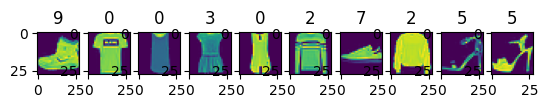

In [3]:
fig,axes = plt.subplots(1,10)
for i,ax in enumerate(axes):
    axes[i].imshow(train_images[i])
    axes[i].set_title(train_labels[i])

Now what we have are lists `train_images` and `train_labels` containing the images and labels for the training set, and the same for the validation set.

1. Compute a HOG descriptor for each image to make two lists, `train_descriptors` and `val_descriptors` (```skimage.feature.hog```).

In [4]:
from skimage.feature import hog

train_descriptors = []
for img in train_images:
    descriptor = hog(img)
    train_descriptors.append(descriptor)

val_descriptors = []
for img in val_images:
    descriptor = hog(img)
    val_descriptors.append(descriptor)

2. Build a k-nearest neighbors classifier on the training set (```sklearn.neighbors.KNeighborsClassifier```).

This model will find the $k$ nearest neighbors to the query point and output the most common label.  Use the default value of $k$.

Run the model on the test set and print out the accuracy (```sklearn.metrics.accuracy_score``` or simply use ```model.score```).

In [5]:
model = KNeighborsClassifier()
model.fit(train_descriptors, train_labels)

accuracy = model.score(val_descriptors, val_labels)
print("Accuracy:", accuracy)

Accuracy: 0.8295


3. Test $k$ from 1 to 101 in increments of 10 and make a plot of the train and test accuracy versus $k$.  Analyze the trade-off between over- and underfitting changes as $k$ increases.  Which is the best setting of $k$?

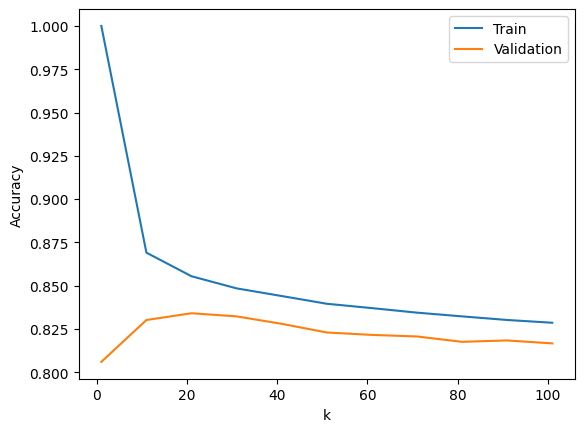

Best k: 21


In [6]:
ks = range(1, 102, 10)
train_scores = []
val_scores = []

for k in ks:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(train_descriptors, train_labels)

    train_scores.append(model.score(train_descriptors, train_labels))
    val_scores.append(model.score(val_descriptors, val_labels))

plt.plot(ks, train_scores, label="Train")
plt.plot(ks, val_scores, label="Validation")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print("Best k:", ks[val_scores.index(max(val_scores))])